# Парная линейная регрессия

**Цель работы:** познакомиться с моделью парной линейной регрессии и методом градиентного спуска.

**Содержание работы:**
1. Найти оценки параметров модели парной линейной регрессии прямыми вычислениями и получить с помощью модели прогнозы результативного признака.
2. Найти оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска.
3. Оценить качество построенной модели, сравнив на графике обучающую выборку и прогнозы.
4. Построить кривые обучения.

In [1]:
# Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Исходные данные: x — расходы на рекламу, Y — объемы продаж
x = np.array([3, 5, 7, 6, 9])
Y = np.array([3, 7, 11, 14, 15])
display(x, Y)

array([3, 5, 7, 6, 9])

array([ 3,  7, 11, 14, 15])

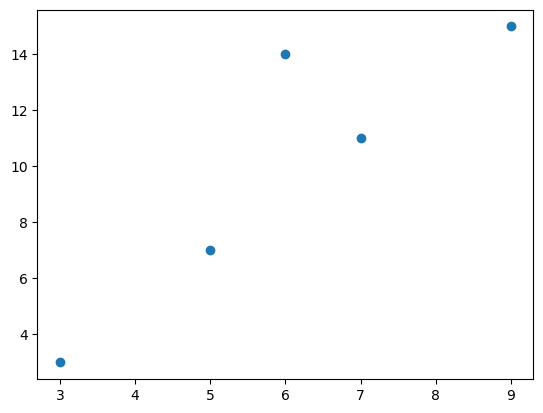

In [3]:
# Изобразим исходные данные на графике
plt.figure()
plt.scatter(x, Y)
plt.show()

In [4]:
# Вычислим оценки коэффициентов парной линейной регрессии по формулам
# a1 = cov(x, Y) / var(x), a0 = Y_mean - a1 * x_mean
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean())**2).mean()
a0 = Y.mean() - a1 * x.mean()
print("Модель линейной регрессии: Y^ =", a0, "+", a1, "* x")

Модель линейной регрессии: Y^ = -2.0 + 2.0 * x


In [5]:
# Дадим серию прогнозов Y^ для x от 3 до 9 с шагом 1
x_space = np.linspace(3, 9, 7)
print(x_space)
Y_pred = a0 + a1 * x_space
print(Y_pred)

[3. 4. 5. 6. 7. 8. 9.]
[ 4.  6.  8. 10. 12. 14. 16.]


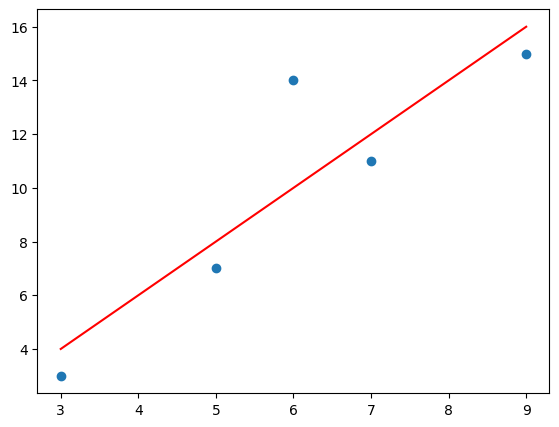

In [6]:
# Изобразим на графике исходные данные и прогнозы
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')
# ax.scatter(x_space, Y_pred)

In [7]:
# Реализуем шаг градиентного спуска в модели парной линейной регрессии
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((self.predict(x) - Y)**2).mean()

    def fit(self, x, Y):
        alpha = 0.1
        dT_a0 = -2 * sum((Y - self.predict(x)))
        dT_a1 = -2 * sum((Y - self.predict(x)) * x)
        self.a0 -= alpha * dT_a0
        self.a1 -= alpha * dT_a1

In [8]:
# Получим прогнозы до градиентного спуска с начальными значениями параметров
regr = SimpleRegression()
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print(regr.MSE(x, Y))

0
0
0
0
0
120.0


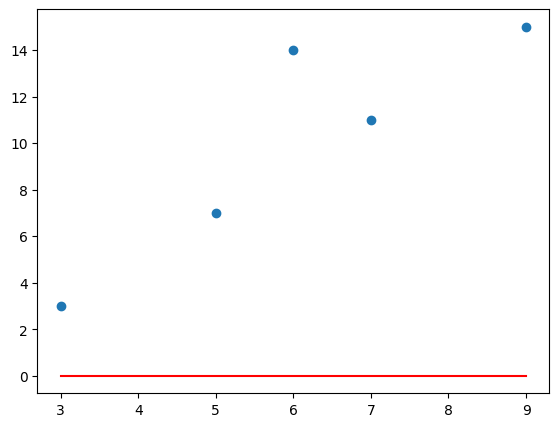

In [9]:
# Выведем прогнозы до градиентного спуска на графике
x_space = np.linspace(3, 9, 7)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

MSE после первого шага градиентного спуска: 183892.0


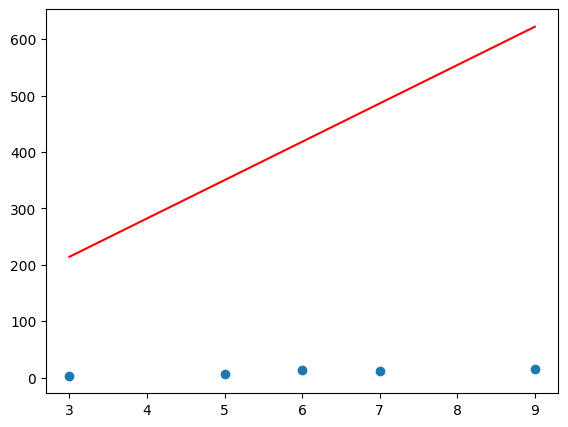

In [10]:
# Реализуем шаг градиентного спуска
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска:", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

In [11]:
# Реализуем цикл градиентного спуска
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((Y - self.predict(x))**2).mean()

    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()

    def MAPE(self, x, Y):
        return abs((Y - self.predict(x)) / Y).mean()

    def fit(self, x, Y, alpha=0.001, epsylon=0.01, max_steps=5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2 * sum((Y - self.predict(x)))
            dT_a1 = -2 * sum((Y - self.predict(x)) * x)
            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

In [12]:
# Запустим цикл градиентного спуска с заданной точностью 5
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.001, epsylon=5)

5.004697916218
8.190462542210001
11.376227168202002
9.783344855206002
14.561991794194002
MSE после градиентного спуска: 4.709918696051655


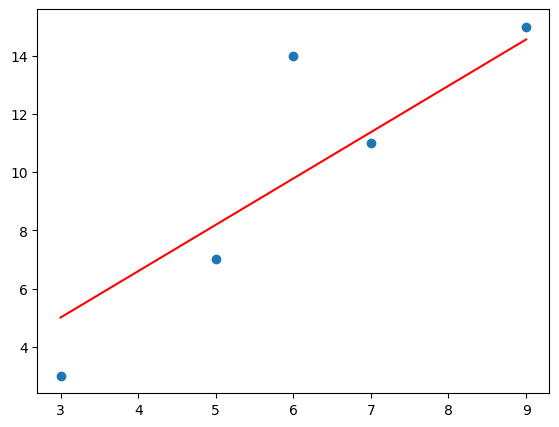

In [13]:
# Выведем график прогнозов и вычислим MSE
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print("MSE после градиентного спуска:", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

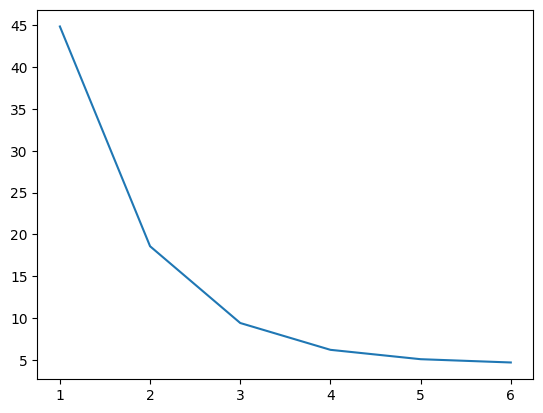

In [14]:
# Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

In [15]:
# Запустим цикл градиентного спуска с заданной точностью 0.05
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.001, epsylon=0.05)

MSE после градиентного спуска: 4.000028517306817


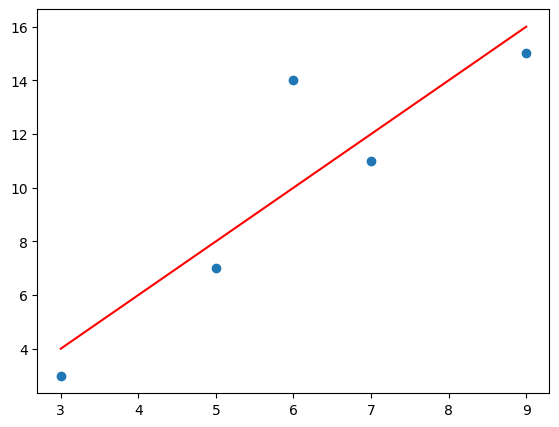

In [16]:
# Выведем график прогнозов и вычислим MSE
print("MSE после градиентного спуска:", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

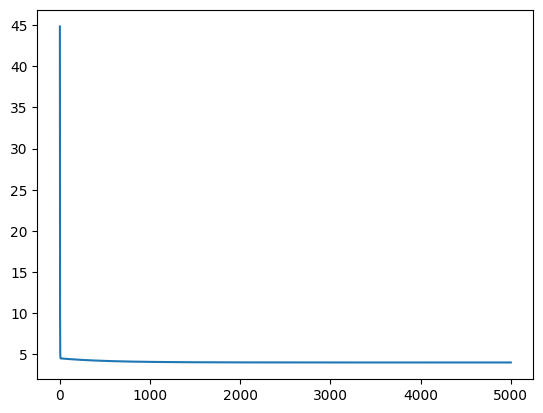

In [17]:
# Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

MSE после градиентного спуска: 4.1903709155046345


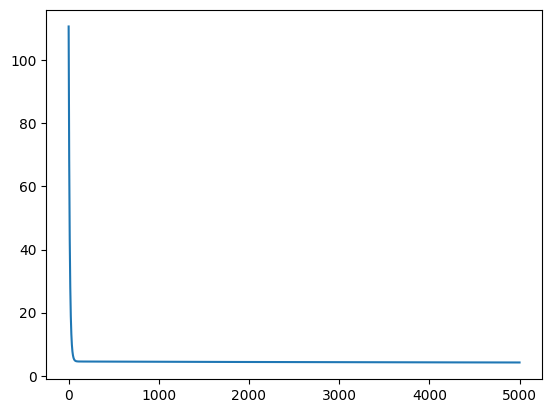

In [18]:
# Запустим цикл градиентного спуска с разными значениями скорости обучения
# alpha=0.0001, 0.01, 0.1, 1, 10, ...
# с различной допустимой точностью epsylon = 0.001, 0.5, 5,
# с различным максимальным количеством шагов max_steps
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.0001, epsylon=0.01, max_steps=5000)
print("MSE после градиентного спуска:", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
plt.figure()
plt.plot(steps, errors)

## Задание для самостоятельной работы

Загрузите файл `Гиперспектр кукурузы.csv` (с помощью `pd.read_csv`).

1. Вычислите аналитическим путём оценки коэффициентов парной линейной регрессии и постройте её график.
2. Найдите оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей, сравнив на графике обучающую выборку и прогнозы.

In [20]:
# Загружаем данные
gipers = pd.read_csv(r"Гиперспектр кукурузы.csv")
gipers.head()
# Y = gipers['Spectr']
# x = gipers['wavelength']

,,wavelength;Spectr
397,32;0,2.0
399,54;0,3.0
401,76;0,3.0
403,98;0,5.0
406,2;0,5.0


   wavelength  Spectr
0      397.32    0.02
1      399.54    0.03
2      401.76    0.03
3      403.98    0.05
4      406.20    0.05

Аналитическая модель: Y = -0.1834 + 0.000668 * x


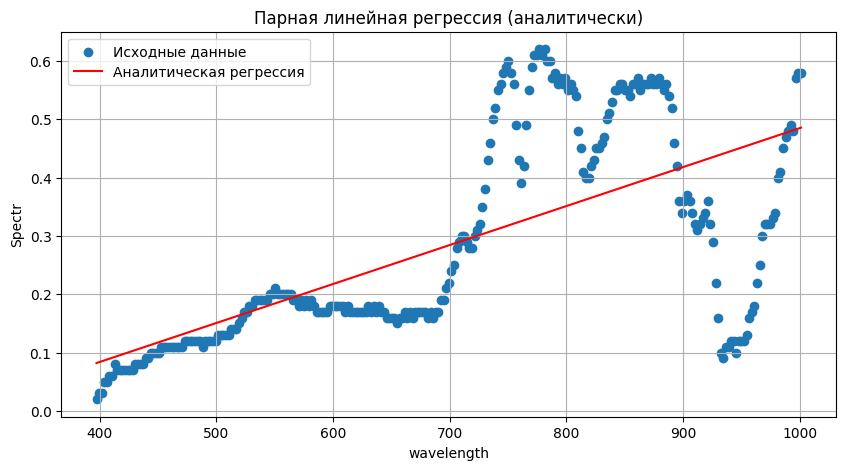

In [27]:

#Загрузка данных
df = pd.read_csv('Гиперспектр кукурузы.csv', sep=';', decimal=',', encoding='utf-8-sig')
print(df.head())

x = df['wavelength'].values   # признак
Y = df['Spectr'].values       # целевая переменная

# Аналитическое решение (метод наименьших квадратов)
x_mean = x.mean()
Y_mean = Y.mean()

# коэффициент наклона a1 = cov(x, Y) / var(x)
a1 = np.sum((x - x_mean) * (Y - Y_mean)) / np.sum((x - x_mean) ** 2)
# свободный член a0 = Y_mean - a1 * x_mean
a0 = Y_mean - a1 * x_mean

print(f'\nАналитическая модель: Y = {a0:.4f} + {a1:.6f} * x')

Y_pred_analytic = a0 + a1 * x

# График аналитической регрессии
plt.figure(figsize=(10, 5))
plt.scatter(x, Y, label='Исходные данные')
plt.plot(x, Y_pred_analytic, 'r', label='Аналитическая регрессия')
plt.xlabel('wavelength')
plt.ylabel('Spectr')
plt.title('Парная линейная регрессия (аналитически)')
plt.legend()
plt.grid(True)
plt.show()


In [29]:
# ------------------------------------------------------------
# Класс линейной регрессии с корректными градиентами (mean, а не sum)
# и с записью истории обучения
# ------------------------------------------------------------
class SimpleRegressionGD(object):
    def __init__(self):
        self.a0 = 0.0
        self.a1 = 0.0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return np.mean((Y - self.predict(x)) ** 2)

    def MAE(self, x, Y):
        return np.mean(np.abs(Y - self.predict(x)))

    def MAPE(self, x, Y):
        return np.mean(np.abs((Y - self.predict(x)) / Y))

    def fit(self, x, Y, alpha=0.1, epsylon=1e-10, max_steps=20000):
        """Градиентный спуск. Градиенты через mean — не зависят от размера выборки."""
        steps, errors = [], []
        for step in range(1, max_steps + 1):
            Y_pred = self.predict(x)
            # ВАЖНО: mean, а не sum — иначе при n≈300 и alpha=0.05 будет NaN
            dT_a0 = -2 * np.mean(Y - Y_pred)
            dT_a1 = -2 * np.mean((Y - Y_pred) * x)
            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1

            err = self.MSE(x, Y)
            steps.append(step)
            errors.append(err)
            if err < epsylon:
                break
        return steps, errors


# Нормализация x
x_mean = x.mean()
x_std  = x.std()
x_norm = (x - x_mean) / x_std
print(f'x_mean = {x_mean:.4f}, x_std = {x_std:.4f}')

# Обучение на нормализованном x
regr = SimpleRegressionGD()
steps, errors = regr.fit(x_norm, Y, alpha=0.1, epsylon=1e-10, max_steps=20000)

print(f'\nГрадиентный спуск (норм. x): a0_norm = {regr.a0:.6f}, a1_norm = {regr.a1:.6f}')
print(f'MSE после GD: {regr.MSE(x_norm, Y):.8f}')
print(f'Шагов выполнено: {len(steps)}')

# Пересчёт коэффициентов к исходному масштабу:
# Y = a0_norm + a1_norm * (x - x_mean)/x_std
#   = (a0_norm - a1_norm*x_mean/x_std) + (a1_norm/x_std) * x
a0_gd = regr.a0 - regr.a1 * x_mean / x_std
a1_gd = regr.a1 / x_std

print(f'Градиентная модель (исходный x): Y = {a0_gd:.6f} + {a1_gd:.8f} * x')


x_mean = 699.2400, x_std = 174.9533

Градиентный спуск (норм. x): a0_norm = 0.283773, a1_norm = 0.116896
MSE после GD: 0.01768411
Шагов выполнено: 20000
Градиентная модель (исходный x): Y = -0.183428 + 0.00066816 * x


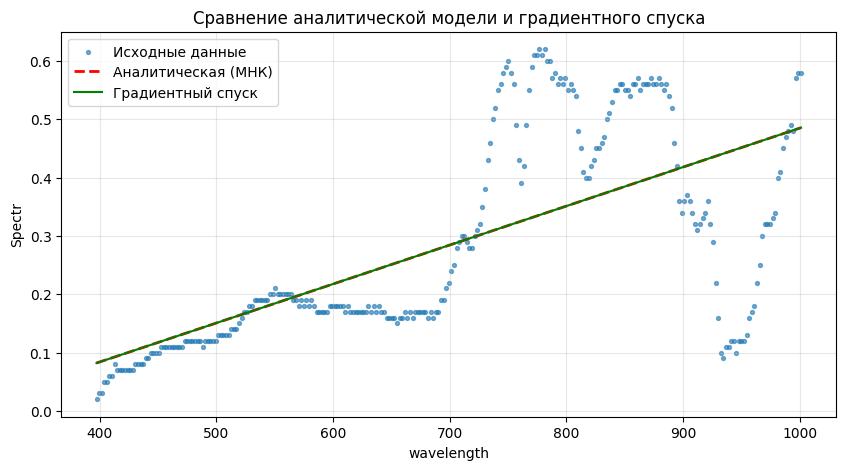

In [30]:
# Предсказания градиентной модели в исходном масштабе
Y_pred_gd = a0_gd + a1_gd * x

# График сравнения моделей
plt.figure(figsize=(10, 5))
plt.scatter(x, Y, s=8, alpha=0.6, label='Исходные данные')
plt.plot(x, Y_pred_analytic, 'r--', linewidth=2, label='Аналитическая (МНК)')
plt.plot(x, Y_pred_gd, 'g-', linewidth=1.5, label='Градиентный спуск')
plt.xlabel('wavelength')
plt.ylabel('Spectr')
plt.title('Сравнение аналитической модели и градиентного спуска')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
def metrics(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, mae, mape, r2

mse_a, mae_a, mape_a, r2_a = metrics(Y, Y_pred_analytic)
mse_g, mae_g, mape_g, r2_g = metrics(Y, Y_pred_gd)

print('Качество аналитической модели (МНК):')
print(f'  MSE  = {mse_a:.6f}')
print(f'  MAE  = {mae_a:.6f}')
print(f'  MAPE = {mape_a:.4f}')
print(f'  R²   = {r2_a:.4f}')

print('\nКачество модели градиентного спуска:')
print(f'  MSE  = {mse_g:.6f}')
print(f'  MAE  = {mae_g:.6f}')
print(f'  MAPE = {mape_g:.4f}')
print(f'  R²   = {r2_g:.4f}')

print('\nРазница между моделями:')
print(f'  Δa0 = {abs(a0 - a0_gd):.2e}')
print(f'  Δa1 = {abs(a1 - a1_gd):.2e}')
print(f'  ΔMSE = {abs(mse_a - mse_g):.2e}')

Качество аналитической модели (МНК):
  MSE  = 0.017684
  MAE  = 0.096834
  MAPE = 0.4338
  R²   = 0.4359

Качество модели градиентного спуска:
  MSE  = 0.017684
  MAE  = 0.096834
  MAPE = 0.4338
  R²   = 0.4359

Разница между моделями:
  Δa0 = 1.67e-16
  Δa1 = 1.08e-19
  ΔMSE = 0.00e+00


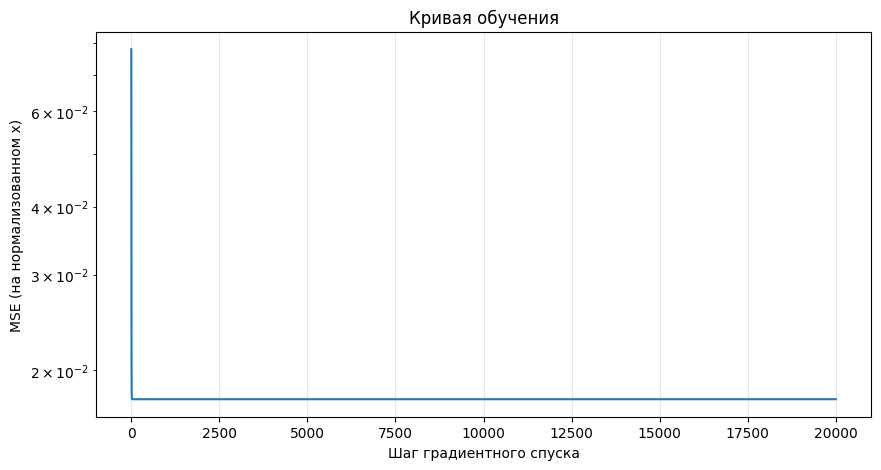

In [32]:
plt.figure(figsize=(10, 5))
plt.plot(steps, errors)
plt.xlabel('Шаг градиентного спуска')
plt.ylabel('MSE (на нормализованном x)')
plt.title('Кривая обучения')
plt.grid(True, alpha=0.3)
plt.yscale('log')  # лог-шкала, чтобы было видно сходимость
plt.show()